# ResNet-50 thresholds for Macaroni 1 and PCB 2
Load the selected fine-tuned model and inspect these two products. Choose thresholds using the same validation images held out from this model's training. Compare with its original shared threshold on test images afterward.

Run top to bottom on BigMac using dl_gpu. This notebook performs inference only. The saved model and VisA images must already exist locally. Each product has only 12 validation defects, so a threshold may perform differently on test images. Previous test inspection makes this an exploratory experiment.


## 1. Settings and saved model

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import ResNet50_Weights, resnet50

PRODUCTS = ["macaroni1", "pcb2"]
RECALL_TARGETS = [0.90, 1.00]
BATCH_SIZE = 16
DATA_DIR = Path("visa_data")
MODEL_DIR = Path("results/full_visa_resnet50_parallel")
OUTPUT_DIR = Path("results/macaroni1_pcb2_recall_targets")
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)

selected = pd.read_csv(MODEL_DIR / "selected_run.csv", index_col=0)["value"]
original_threshold = float(selected["threshold"])
checkpoint = Path(selected["checkpoint"])
assert checkpoint.is_file(), f"Missing saved model: {checkpoint}"
model = resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 1)
model.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True))
model = model.to(device).eval()
preprocess = ResNet50_Weights.DEFAULT.transforms()
print("Using", device, "Original threshold", original_threshold)


Using cuda:0 Original threshold 0.0027781573589891


## 2. Recreate the validation split
Split the complete training list first, exactly as in the training notebook. Then select the two products.

In [2]:
rows = pd.read_csv(DATA_DIR / "2cls_highshot.csv")
training = rows[rows["split"] == "train"].reset_index(drop=True)
strata = training["object"] + "_" + training["label"]
_, validation_indices = train_test_split(
    range(len(training)), test_size=0.2, stratify=strata,
    random_state=int(selected["split_seed"]),
)
validation = training.iloc[validation_indices]
validation = validation[validation["object"].isin(PRODUCTS)].reset_index(drop=True)
testing = rows[(rows["split"] == "test") & rows["object"].isin(PRODUCTS)].reset_index(drop=True)
assert set(validation["image"]).isdisjoint(testing["image"])
display(pd.crosstab(validation["object"], validation["label"]))

class ImageDataset(Dataset):
    def __init__(self, table):
        self.table = table.reset_index(drop=True)

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        path = DATA_DIR / self.table.iloc[index]["image"]
        with Image.open(path) as image:
            return preprocess(image.convert("RGB"))

@torch.no_grad()
def predict(table):
    probabilities = []
    for images in DataLoader(ImageDataset(table), batch_size=BATCH_SIZE, shuffle=False):
        scores = model(images.to(device)).squeeze(1).sigmoid()
        probabilities.extend(scores.cpu().tolist())
    result = table[["object", "image", "label"]].copy()
    result["label"] = result["label"].map({"normal": 0, "anomaly": 1})
    result["score"] = probabilities
    return result

validation_scores = predict(validation)


label,anomaly,normal
object,,
macaroni1,12,120
pcb2,12,120


## 3. Inspect validation scores and false alarms

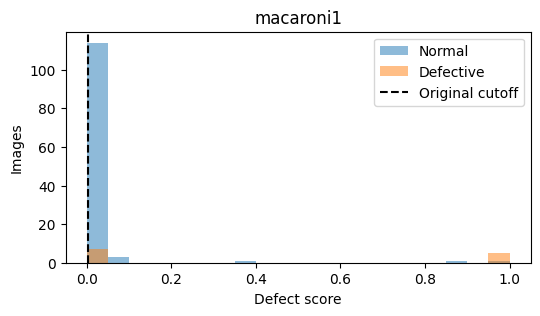

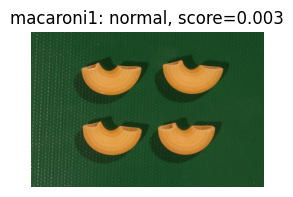

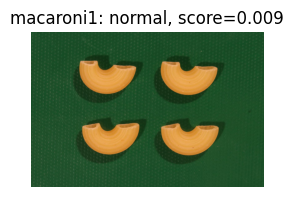

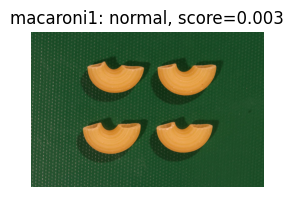

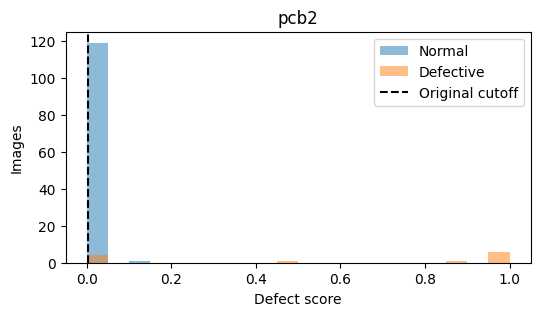

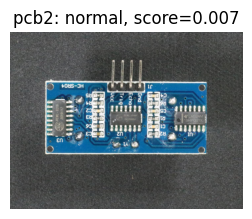

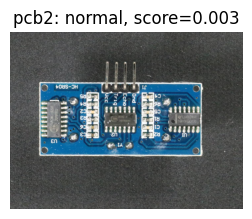

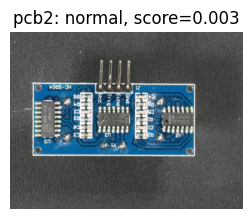

In [3]:
for product in PRODUCTS:
    group = validation_scores[validation_scores["object"] == product]
    plt.figure(figsize=(6, 3))
    for label, name in [(0, "Normal"), (1, "Defective")]:
        plt.hist(group.loc[group["label"] == label, "score"], bins=20, range=(0, 1), alpha=0.5, label=name)
    plt.axvline(original_threshold, color="black", linestyle="--", label="Original cutoff")
    plt.title(product)
    plt.xlabel("Defect score")
    plt.ylabel("Images")
    plt.legend()
    plt.show()

    false_alarms = group[(group["label"] == 0) & (group["score"] >= original_threshold)]
    for row in false_alarms.head(3).itertuples():
        with Image.open(DATA_DIR / row.image) as image:
            plt.figure(figsize=(3, 3))
            plt.imshow(image)
            plt.title(f"{product}: normal, score={row.score:.3f}")
            plt.axis("off")
            plt.show()


## 4. Compare validation recall targets
Compare the original shared cutoff with product cutoffs targeting 90% and 100% validation recall. With 12 validation defects, these require detecting 11 and 12 respectively. The 100% cutoff is the lowest defect score in validation. It can increase false alarms and does not guarantee 100% recall on new images.


In [4]:
def summarize(group, threshold):
    predicted = group["score"] >= threshold
    tn, fp, fn, tp = confusion_matrix(group["label"], predicted, labels=[0, 1]).ravel()
    return {
        "threshold": threshold, "detected": tp, "missed": fn, "false_alarms": fp,
        "recall": tp / (tp + fn),
        "precision": tp / (tp + fp) if tp + fp else 0.0,
    }

thresholds = {}
comparison_rows = []
for product in PRODUCTS:
    group = validation_scores[validation_scores["object"] == product]
    defect_scores = group.loc[group["label"] == 1, "score"].sort_values(ascending=False)
    methods = {"Original": original_threshold}
    for target in RECALL_TARGETS:
        required = math.ceil(target * len(defect_scores))
        methods[f"Target {target:.0%}"] = float(defect_scores.iloc[required - 1])
    thresholds[product] = methods
    for method, cutoff in methods.items():
        comparison_rows.append({
            "product": product, "method": method, **summarize(group, cutoff),
        })
validation_comparison = pd.DataFrame(comparison_rows)
display(validation_comparison.round(4))


,product,method,threshold,detected,missed,false_alarms,recall,precision
0,macaroni1,Original,0.0028,12,0,68,1.0000,0.1500
1,macaroni1,Target 90%,0.0100,11,1,14,0.9167,0.4400
2,macaroni1,Target 100%,0.0061,12,0,32,1.0000,0.2727
3,pcb2,Original,0.0028,12,0,75,1.0000,0.1379
4,pcb2,Target 90%,0.0125,11,1,7,0.9167,0.6111
5,pcb2,Target 100%,0.0103,12,0,14,1.0000,0.4615


## 5. Evaluate all three preselected approaches
Apply the original, 90%, and 100% validation-recall cutoffs to the same test images. Show per-product and combined counts. Negative changes mean fewer errors. This is an exploratory comparison using a test set already examined in earlier runs. Results are saved in a new folder.


In [5]:
test_scores = predict(testing)
result_rows = []
for product in PRODUCTS:
    group = test_scores[test_scores["object"] == product]
    for method, cutoff in thresholds[product].items():
        result_rows.append({"product": product, "method": method, **summarize(group, cutoff)})
results = pd.DataFrame(result_rows)
display(results.round(4))

# Combine the counts to compare the total inspection workload.
totals = results.groupby("method")[["detected", "missed", "false_alarms"]].sum()
totals["recall"] = totals["detected"] / (totals["detected"] + totals["missed"])
totals["change_in_missed"] = totals["missed"] - totals.loc["Original", "missed"]
totals["change_in_false_alarms"] = totals["false_alarms"] - totals.loc["Original", "false_alarms"]
display(totals.round(4))

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
validation_scores.to_csv(OUTPUT_DIR / "validation_scores.csv", index=False)
validation_comparison.to_csv(OUTPUT_DIR / "validation_thresholds.csv", index=False)
test_scores.to_csv(OUTPUT_DIR / "test_scores.csv", index=False)
results.to_csv(OUTPUT_DIR / "test_comparison.csv", index=False)
totals.to_csv(OUTPUT_DIR / "combined_comparison.csv")
print("Saved results to", OUTPUT_DIR.resolve())


,product,method,threshold,detected,missed,false_alarms,recall,precision
0,macaroni1,Original,0.0028,38,2,228,0.950,0.1429
1,macaroni1,Target 90%,0.0100,34,6,35,0.850,0.4928
2,macaroni1,Target 100%,0.0061,35,5,90,0.875,0.2800
3,pcb2,Original,0.0028,39,1,275,0.975,0.1242
4,pcb2,Target 90%,0.0125,35,5,34,0.875,0.5072
5,pcb2,Target 100%,0.0103,36,4,52,0.900,0.4091


,detected,missed,false_alarms,recall,change_in_missed,change_in_false_alarms
method,,,,,,
Original,77,3,503,0.9625,0,0
Target 100%,71,9,142,0.8875,6,-361
Target 90%,69,11,69,0.8625,8,-434


Saved results to /home/russ/defect-detection-active-learning/results/macaroni1_pcb2_recall_targets
